# `finished-fish-data.ipynb`

Connor Shrader / 08-19-2025

Finish cleaning the barcode data before running model analysis. The output of this notebook is the `real.csv` dataframe in `./simulated-data`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import json
import os

import testis_model as tm
from saving_loading import combine_and_save, scenario_exists

## Load and finalize the fish data

In [2]:
def experimental_scenario(experiment, name, file = 'final_data'):
    data_path = f'../experiments/{experiment}/{file}.csv'
    all_data = pd.read_csv(data_path)
    
    fish_arr = []
    barcodes_dict = dict()
    
    sample_map = tm.data_processing.sample_map
    
    fishes = [f for f in all_data['fish'].unique() if 'ctrl' not in f]
    nrow = len(fishes) // 6 + 1
    fig, ax = plt.subplots(nrow, 6, figsize = (15, 9))
    ax2 = ax.ravel()
    
    for i, fish in enumerate(fishes):
        fish_label = int(fish[4:])
        fish_data = all_data.query('fish == @fish').copy()
        barcodes = tm.data_processing.get_barcodes(fish_data)
        unedited_index = tm.data_processing.where_unedited(barcodes)
        
        fish_table = tm.data_processing.convert_to_tuple_format(fish_data, n_sperm = 472)
        fish_table['time'] = fish_table['time'].map(sample_map)
        
        tm.visualize.plot(fish_table, ax2[i], unedited_index = unedited_index)
        
        fish_table.insert(0, 'scenario', name)
        fish_table.insert(1, 'fish', fish_label)
        fish_table.insert(2, 'duplicate', 0)
    
        ax2[i].set_xlabel('')
        ax2[i].set_ylabel('')
        ax2[i].set_yticks([])
        ax2[i].set_title(fish)
    
        fish_arr.append(fish_table)
        barcodes_dict[fish_label] = barcodes

        # Check if scenario exists, and if not, create a directory
        scenario_exists(name, makedir = True)
            
        df = combine_and_save(fish_arr, name)
        df.head()
    
        barcodes_dict2 = {k: v.tolist() for k, v in barcodes_dict.items()}
        with open(os.path.join("scenarios", name, "barcodes.json"), 'w') as f:
            json.dump(barcodes_dict2, f)

    
    plt.tight_layout()
    plt.savefig(os.path.join("scenarios", name, f"{name}.png"), bbox_inches = 'tight')
    # plt.close()

    return df, fig

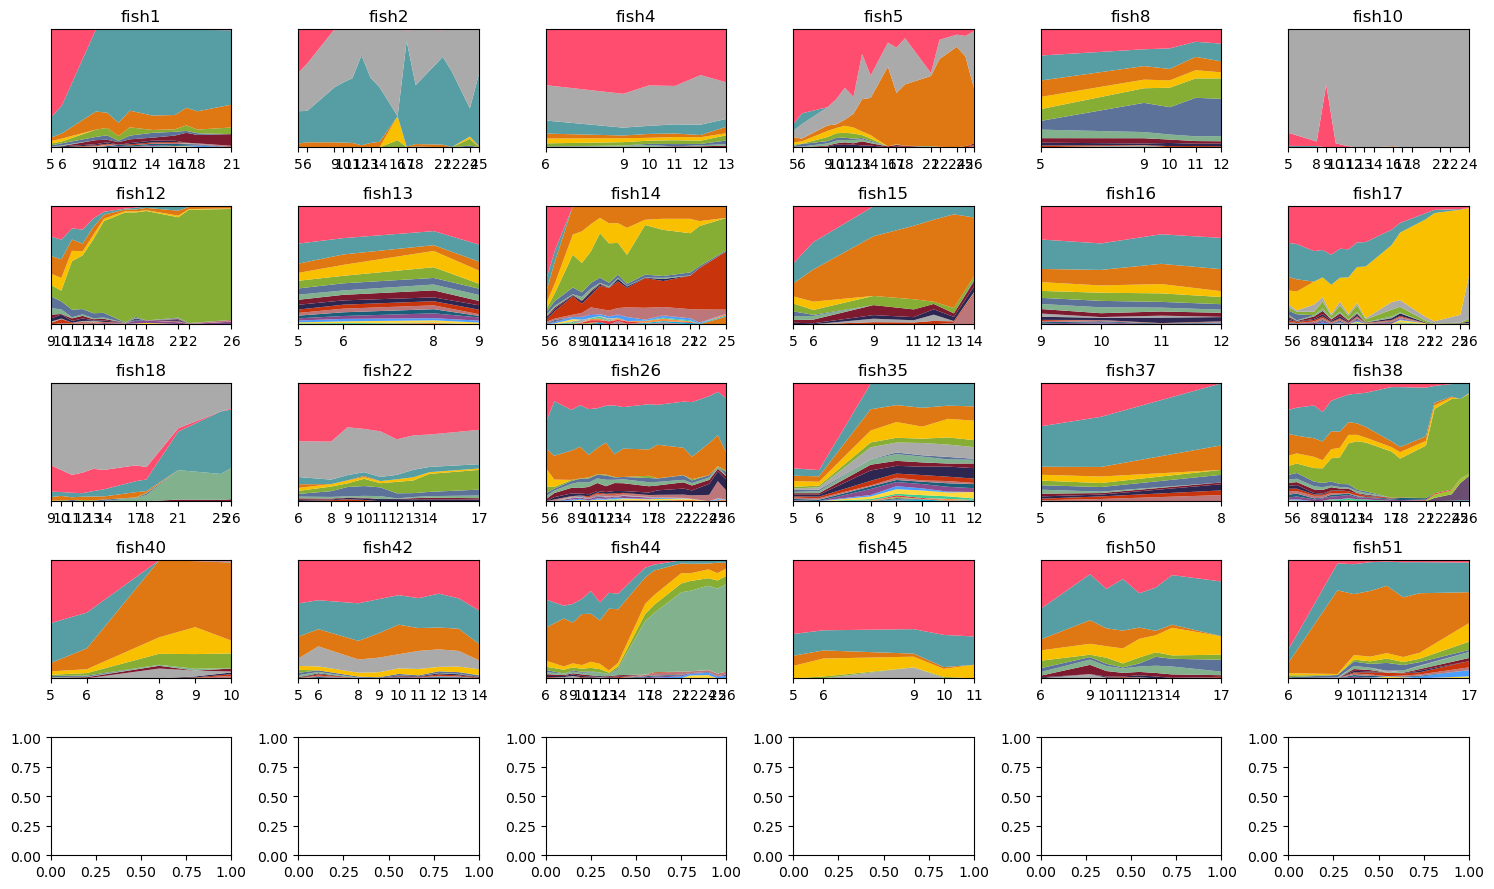

In [3]:
name = 'no_cluster'
experiment = 'no_cluster'
file = 'final_data'
df, fig = experimental_scenario(experiment, name, file = file)
plt.show()

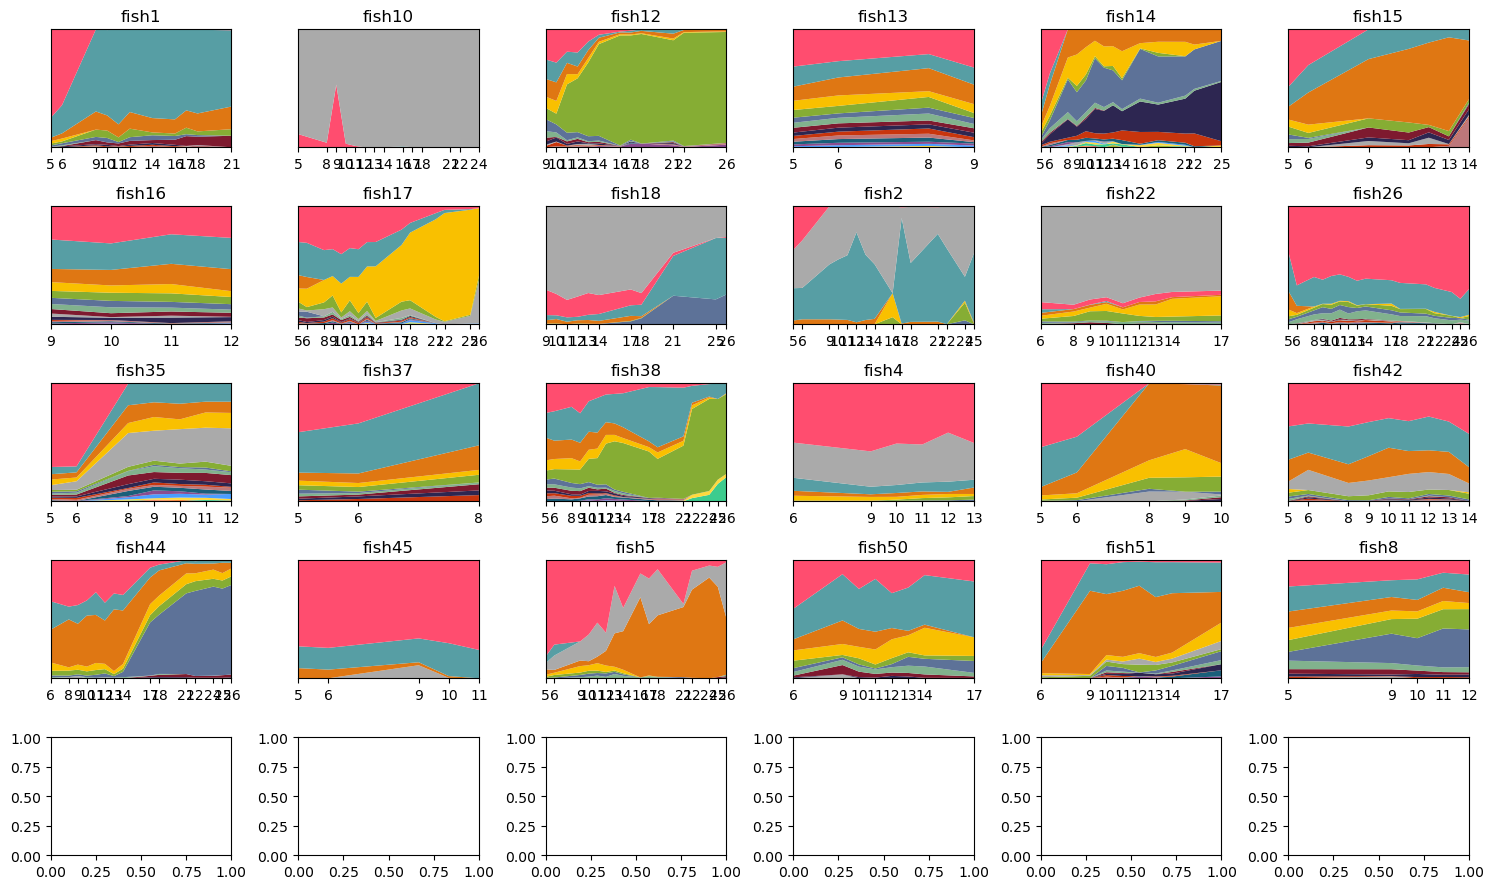

In [4]:
name = 'full_pipeline'
experiment = 'full_pipeline'
file = 'final_data'
df, fig = experimental_scenario(experiment, name, file = file)
plt.show()

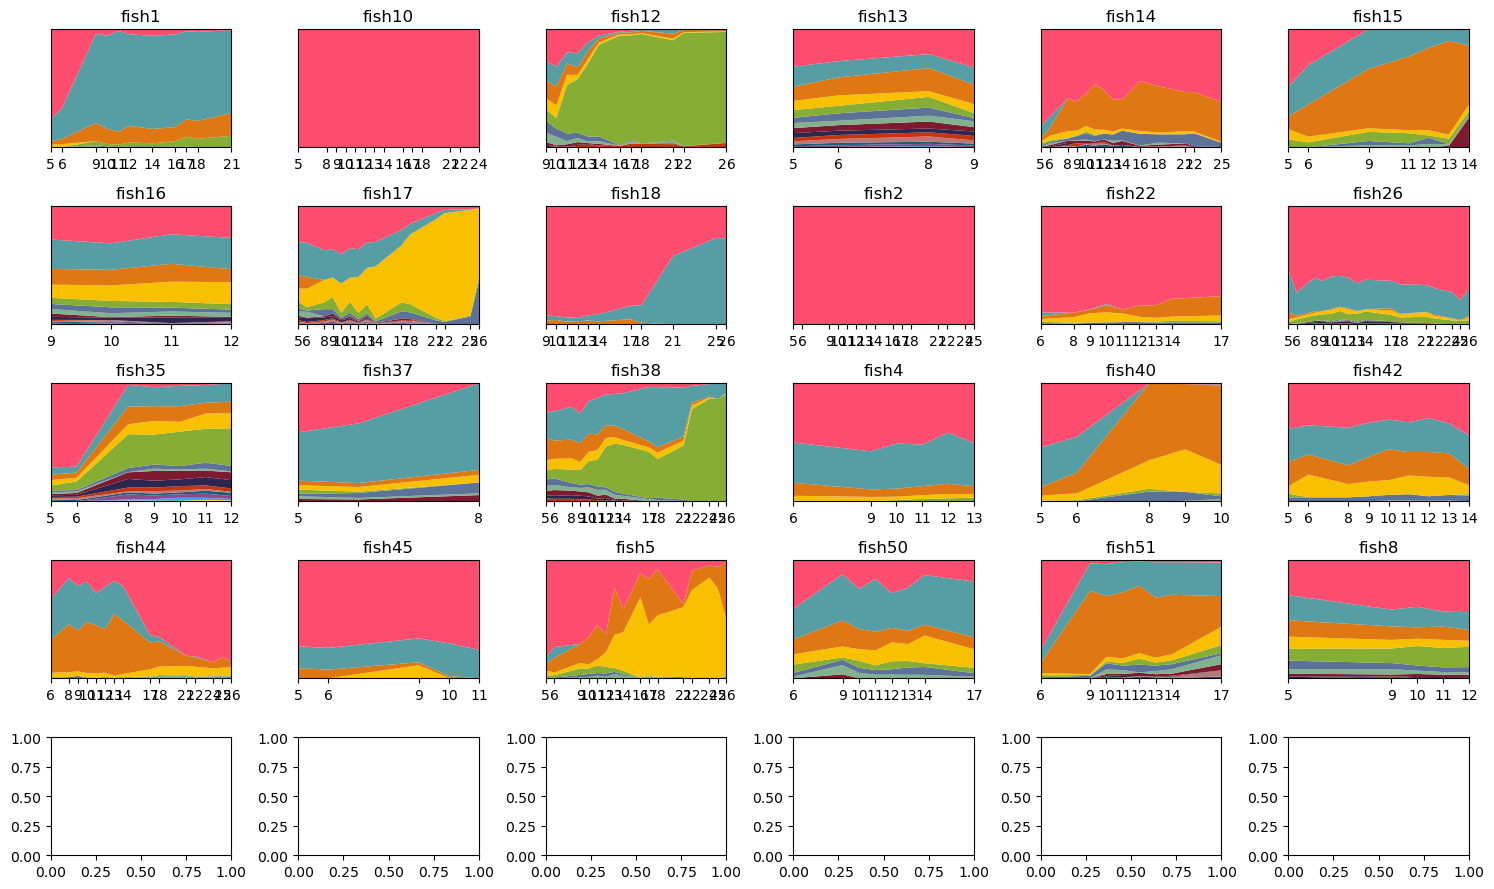

In [5]:
name = 'full_pipeline_trunc'
experiment = 'full_pipeline'
file = 'final_data_trunc'
df, fig = experimental_scenario(experiment, name, file = file)
plt.show()

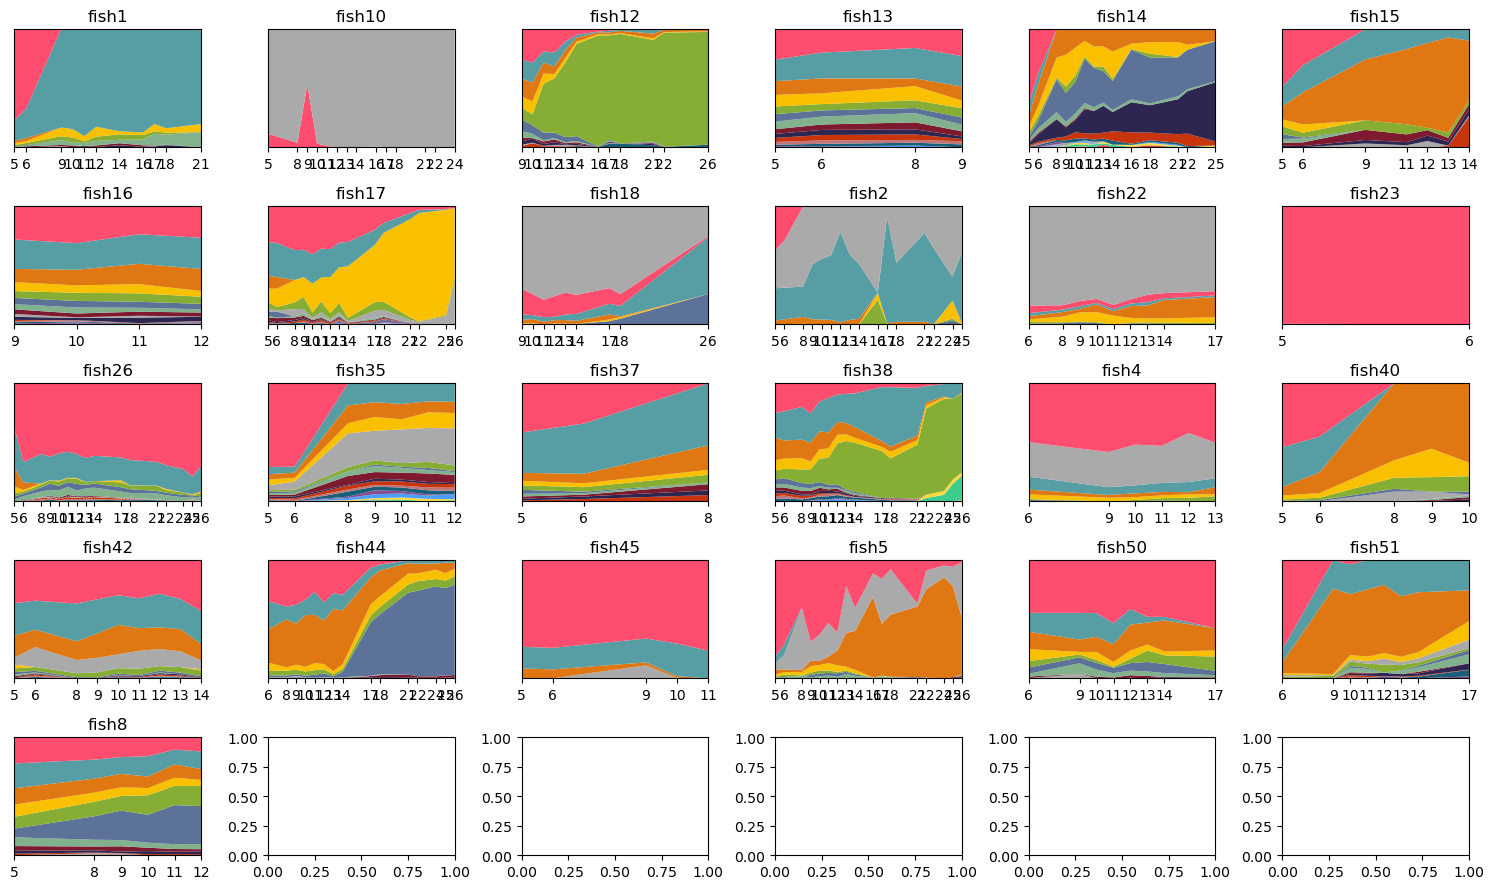

In [6]:
name = 'full_pipeline_MP0.95'
experiment = 'full_pipeline_MP0.95'
file = 'final_data'
df, fig = experimental_scenario(experiment, name, file = file)
plt.show()